In [ ]:
import pandas as pd, matplotlib, numpy, torch, sklearn
print(sklearn.__version__)


1.6.1


In [ ]:
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing(as_frame=True)
df = housing.frame


In [ ]:
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [ ]:
from sklearn.preprocessing import StandardScaler

x = df.drop(columns=['MedHouseVal'])   # everything except the target in x
y = df['MedHouseVal']                  # target, i.e.what we're trying to predict, in y


In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)


In [ ]:
scaler = StandardScaler()               # create an (unfitted) scaler
x_train_scaled = scaler.fit_transform(x_train)   # fit the scaler only on trainning data and use it to transfrom both trainning and testing data
x_test_scaled = scaler.transform(x_test) # transform only, reuse the SAME fitted scaler, do not re-fit

In [ ]:
x_train_scaled

array([[-0.326196  ,  0.34849025, -0.17491646, ...,  0.05137609,
        -1.3728112 ,  1.27258656],
       [-0.03584338,  1.61811813, -0.40283542, ..., -0.11736222,
        -0.87669601,  0.70916212],
       [ 0.14470145, -1.95271028,  0.08821601, ..., -0.03227969,
        -0.46014647, -0.44760309],
       ...,
       [-0.49697313,  0.58654547, -0.60675918, ...,  0.02030568,
        -0.75500738,  0.59946887],
       [ 0.96545045, -1.07984112,  0.40217517, ...,  0.00707608,
         0.90651045, -1.18553953],
       [-0.68544764,  1.85617335, -0.85144571, ..., -0.08535429,
         0.99543676, -1.41489815]])

In [ ]:
df['age_bucket'] = pd.qcut(df['HouseAge'], q=3, labels=['new', 'medium', 'old']) # create a new categorical column

pd.get_dummies(df['age_bucket'])        # one-hot: 3 new 0/1 columns


,new,medium,old
0,False,False,True
1,True,False,False
2,False,False,True
3,False,False,True
4,False,False,True
...,...,...,...
20635,False,True,False
20636,True,False,False
20637,True,False,False
20638,True,False,False


In [ ]:
df['age_bucket'].cat.codes              # ordinal: single 0/1/2 column


,0
0,2
1,0
2,2
3,2
4,2
...,...
20635,1
20636,0
20637,0
20638,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   MedInc       20640 non-null  float64 
 1   HouseAge     20640 non-null  float64 
 2   AveRooms     20640 non-null  float64 
 3   AveBedrms    20640 non-null  float64 
 4   Population   20640 non-null  float64 
 5   AveOccup     20640 non-null  float64 
 6   Latitude     20640 non-null  float64 
 7   Longitude    20640 non-null  float64 
 8   MedHouseVal  20640 non-null  float64 
 9   age_bucket   20640 non-null  category
dtypes: category(1), float64(9)
memory usage: 1.4 MB


In [ ]:
# we replace the HouseAge with the age bucket, so need to redo the data preprocess
x = df.drop(columns=['MedHouseVal', 'HouseAge'])
x['age_bucket'] = df['age_bucket'].cat.codes
y = df['MedHouseVal']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

x_train.info()
y.info()


<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 14196 to 15795
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      16512 non-null  float64
 1   AveRooms    16512 non-null  float64
 2   AveBedrms   16512 non-null  float64
 3   Population  16512 non-null  float64
 4   AveOccup    16512 non-null  float64
 5   Latitude    16512 non-null  float64
 6   Longitude   16512 non-null  float64
 7   age_bucket  16512 non-null  int8   
dtypes: float64(7), int8(1)
memory usage: 1.0 MB
<class 'pandas.core.series.Series'>
RangeIndex: 20640 entries, 0 to 20639
Series name: MedHouseVal
Non-Null Count  Dtype  
--------------  -----  
20640 non-null  float64
dtypes: float64(1)
memory usage: 161.4 KB


In [ ]:
import torch.nn as nn

model = nn.Linear(in_features=8, out_features=1)
# 8 inputs: 7 numeric + 1 ordinal 'age_bucket' column
# 1 output: the house value
loss_fn = nn.MSELoss()                                  # Mean Squared Error
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)



In [ ]:
x_train_t = torch.tensor(x_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

losses = []                           # keep records of loss every round

for epoch in range(100):
    optimizer.zero_grad()             # clear old gradients
    preds = model(x_train_t)          # forward pass
    loss = loss_fn(preds, y_train_t)  # how wrong are we?
    loss.backward()                   # compute gradients
    optimizer.step()                  # update weights
    losses.append(loss.item())

Text(0.5, 1.0, 'Training Loss')

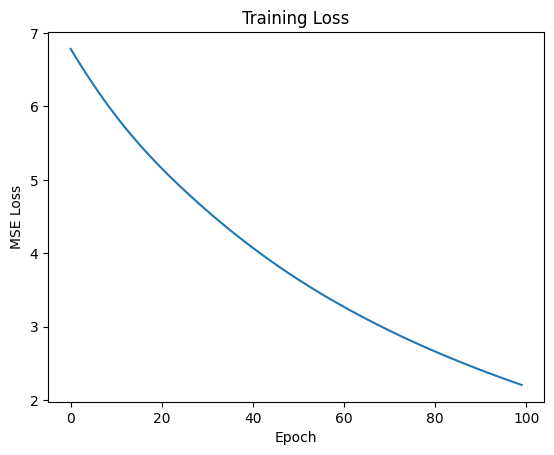

In [ ]:
import matplotlib.pyplot as plt

# plot out the losses
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss')


In [ ]:
wine = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    sep=';'
)
wine['quality_bucket'] = pd.cut(
    wine['quality'], bins=[0, 5, 6, 10],labels=['low', 'medium', 'high']
)

In [ ]:
x_wine = wine.drop(columns=['quality', 'quality_bucket'])
y_wine = wine['quality_bucket'].cat.codes   # ordinal target: 0 / 1 / 2

num_classes = 3   # low / medium / high

model = nn.Linear(in_features=x_wine.shape[1], out_features=num_classes)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [ ]:
x_train_wine, x_test_wine, y_train_wine, y_test_wine = train_test_split(
    x_wine, y_wine, test_size=0.2, random_state=42, stratify=y_wine
)
# stratify=y_wine keeps the low/medium/high proportions roughly equal in both sets
scaler_wine = StandardScaler()
x_train_wine_scaled = scaler_wine.fit_transform(x_train_wine)
x_test_wine_scaled = scaler_wine.transform(x_test_wine)

x_train_t = torch.tensor(x_train_wine_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_wine.values, dtype=torch.long)   # class indices, not floats

In [ ]:
losses = []
for epoch in range(100):
    optimizer.zero_grad()          # clear old gradients
    preds = model(x_train_t)        # forward pass
    loss = loss_fn(preds, y_train_t)  # how wrong are we?
    loss.backward()                 # compute gradients
    optimizer.step()                # update weights
    losses.append(loss.item())

In [ ]:
x_test_wine_t = torch.tensor(x_test_wine_scaled, dtype=torch.float32) # convert it to tensor

from sklearn.metrics import classification_report

y_pred = model(x_test_wine_t).argmax(dim=1)   # pick the highest-scoring class as the result
print(classification_report(y_test_wine, y_pred))

              precision    recall  f1-score   support

           0       0.71      0.81      0.75       149
           1       0.57      0.56      0.56       128
           2       0.65      0.35      0.45        43

    accuracy                           0.65       320
   macro avg       0.64      0.57      0.59       320
weighted avg       0.64      0.65      0.64       320



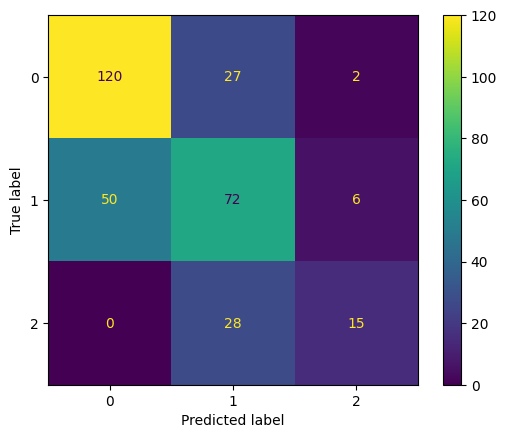

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test_wine, y_pred)
